# 06 · Análisis posterior de test: por qué falla en algunas noches

**Este notebook se hizo después de la evaluación única (`05`) y no la cambia.** Es descriptivo: no se ajusta ni se elige nada, y los resultados de `05` siguen siendo los de la hipótesis. El grupo decidió hacerlo después de ver dos cosas en `05`:
- noches con apnea donde el detector marca mucho menos de lo real (a11, a06, x15) y controles con muchos minutos marcados (c08, b04);
- dos noches de una misma persona (c04, x29) con la mayoría de los minutos excluidos.

Se usan las mismas tablas por minuto y los mismos parámetros fijos que en `05`. De desarrollo se usa la relación entre el nivel de la EDR y el % de apnea, igual que en el análisis de errores de `04` (sección 11).

In [1]:
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr

from src.config import ECG_FILTER, SPLIT_CSV
from src.data import load_apnea_labels, load_ecg
from src.features.detector import c_score, evaluable, load_params, minute_table
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.qrs.beats import record_beats
from src.qrs.rr_clean import clean_rr
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, label_strip, save, setup

setup()
P = load_params(ROOT / "docs" / "parametros_test.json")
split = pd.read_csv(SPLIT_CSV)
CATEG, SUJETO = split.set_index("record").category, split.set_index("record").subject
TEST = split[split.set == "test"].record.tolist()
DEV = split[split.set == "dev"].record.tolist()

def terminos(tab):
    tab = tab.assign(category=tab.record.map(CATEG), subject=tab.record.map(SUJETO))
    tab["C"] = c_score(tab, P)
    tab["termino_rr"] = (tab.P_RR - P["mu1"]) / P["s1"]
    tab["termino_edr"] = P["w"] * (tab.EDR_noche - P["mu2"]) / P["s2"]
    tab["decision"] = (tab.C > P["umbral"]).astype(int)
    tab["evaluado"] = evaluable(tab)
    return tab

with ProcessPoolExecutor(4) as ex:
    T = terminos(pd.concat(list(ex.map(minute_table, TEST)), ignore_index=True))
    D = terminos(pd.concat(list(ex.map(minute_table, DEV)), ignore_index=True))

def auc(x, y):
    x, y = np.asarray(x, float), np.asarray(y, int)
    r = rankdata(x); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) if n1 and n0 else np.nan

def por_noche(tab):
    filas = []
    for r_, g_ in tab.groupby("record"):
        e_ = g_[g_.evaluado]
        filas.append({"record": r_, "categoría": CATEG[r_], "persona": SUJETO[r_],
                      "evaluados (%)": 100 * g_.evaluado.mean(), "apnea real (%)": 100 * e_.label.mean(),
                      "marcado (%)": 100 * e_.decision.mean(), "término EDR": g_.termino_edr.iloc[0],
                      "término RR, minutos normales": e_[e_.label == 0].termino_rr.median(),
                      "término RR, minutos con apnea": e_[e_.label == 1].termino_rr.median(),
                      "AUC dentro de la noche": auc(e_.P_RR, e_.label)})
    return pd.DataFrame(filas).set_index("record")

NT, ND = por_noche(T), por_noche(D)
NT.sort_values("marcado (%)").round(2)

,categoría,persona,evaluados (%),apnea real (%),marcado (%),término EDR,"término RR, minutos normales","término RR, minutos con apnea",AUC dentro de la noche
record,,,,,,,,,
a11,A,S10,100.00,47.84,0.00,-1.20,-1.07,-0.44,0.85
b05,B,S17,88.79,13.95,0.00,-1.72,-0.35,0.56,0.84
x24,C,S25,99.04,0.24,0.00,-1.22,-0.28,1.02,0.89
x11,B,S17,99.78,2.88,0.00,-0.90,-0.53,0.39,0.86
x29,C,S21,14.90,0.00,0.00,-2.12,-0.51,NaN,NaN
c04,C,S21,27.16,0.00,4.76,-0.15,-0.66,NaN,NaN
x06,C,S25,99.32,0.00,9.52,-0.95,-0.09,NaN,NaN
x15,A,S06,100.00,40.32,9.68,-0.15,-1.00,-0.06,0.83
a06,A,S06,100.00,40.71,11.86,-0.24,-0.75,0.02,0.74


**Cómo leer la tabla.** Un minuto se marca como apnea si C = término RR + término EDR supera el umbral (0,49). Como el término de la EDR es el mismo en toda la noche, **el RR de un minuto tiene que superar umbral − término EDR** para que ese minuto se marque. Si el término de la EDR es bajo, la vara del RR queda alta, y al revés. El AUC dentro de la noche dice si el RR ordena bien los minutos de esa noche, independientemente de dónde quede la vara.

## 1. Las noches con apnea subestimadas y los controles sobreestimados

PosixPath('/home/user/TP-PSB-G8/informe/figuras/06_fallas_test.png')

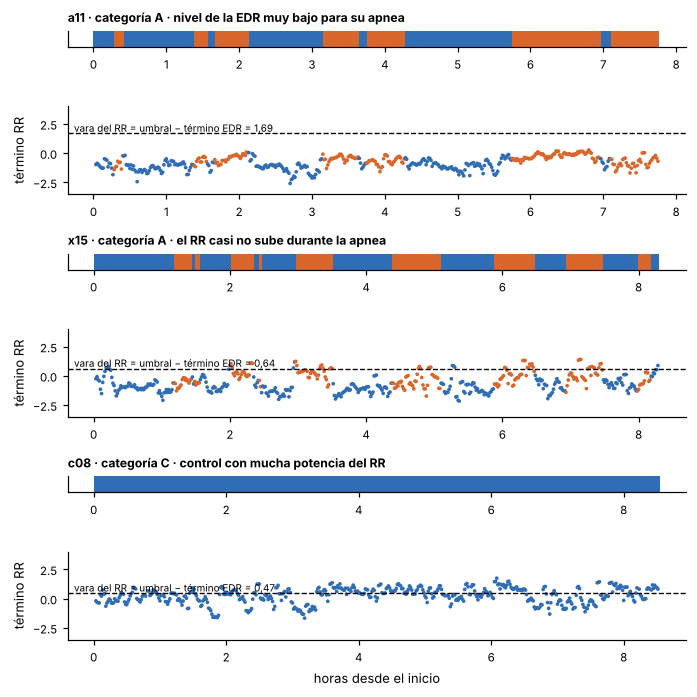

In [2]:
CASOS = [("a11", "nivel de la EDR muy bajo para su apnea"), ("x15", "el RR casi no sube durante la apnea"),
         ("c08", "control con mucha potencia del RR")]
fig, axs = plt.subplots(len(CASOS) * 2, 1, figsize=(ANCHO, 6.4), gridspec_kw={"height_ratios": [0.18, 1] * len(CASOS)})
for k, (r_, motivo) in enumerate(CASOS):
    g_ = T[(T.record == r_) & T.evaluado].sort_values("minute")
    label_strip(axs[2 * k], load_apnea_labels(r_), unit=60)
    axs[2 * k].set_title(f"{r_} · categoría {CATEG[r_]} · {motivo}", fontsize=8)
    ax = axs[2 * k + 1]
    ax.scatter(g_.minute / 60, g_.termino_rr, s=2, c=np.where(g_.label == 1, APNEA, NORMAL))
    vara = P["umbral"] - g_.termino_edr.iloc[0]
    ax.axhline(vara, color="black", ls="--", lw=0.9)
    ax.text(0.01, vara + 0.15, f"vara del RR = umbral − término EDR = {vara:.2f}".replace(".", ","), fontsize=6.5,
            transform=ax.get_yaxis_transform())
    ax.set(ylabel="término RR", ylim=(-3.5, 4))
    axs[2 * k].sharex(ax)
axs[-1].set_xlabel("horas desde el inicio")
fig.tight_layout()
save(fig, "06_fallas_test")

**Qué se ve.**
- **a11** (48 % de apnea real, 0 % marcado). El RR sube en los episodios (naranja) y ordena bien la noche (AUC dentro de la noche 0,85), pero el nivel de la EDR es de los más bajos de test (término −1,20, como el de una noche casi sin apnea). Eso deja la vara en 1,69 y ningún minuto la alcanza. Es el mismo fallo principal que en desarrollo (`04`, sección 11): el nivel de la EDR no corresponde a la cantidad de apnea de la noche.
- **x15** (y a06, la misma persona; ~40 % real y ~10 % marcado). El término de la EDR es casi normal, pero el RR casi no sube durante los episodios (mediana del término RR en apnea −0,06). En esta persona la frecuencia cardíaca responde poco al ciclo de la apnea: el RR ordena bien los minutos (AUC 0,83), pero la diferencia entre apnea y normal es chica.
- **c08** (control, 42 % marcado). La EDR tiene un nivel intermedio, pero el RR de esta persona tiene mucha potencia en la banda incluso sin apnea (mediana del término RR en minutos normales +0,36), y cruza la vara en buena parte de la noche. b04, de la misma persona, se sobreestima por lo mismo.

## 2. ¿Es el mismo patrón que en desarrollo?

En `04` (sección 11) las noches se subestimaban cuando su nivel de EDR quedaba por debajo de lo esperado para su % de apnea. Se repite en test con la recta de desarrollo (nivel de la EDR contra % de apnea): el **residuo** de cada noche de test es su término EDR menos el que le correspondería por su % real de apnea según esa recta. También se mira el nivel del RR en los minutos normales.

ρ (residuo EDR, error) en test: 0.67 · en desarrollo con las mismas definiciones: 0.51
ρ (término RR en minutos normales, error) en test: 0.75 · en desarrollo: 0.40


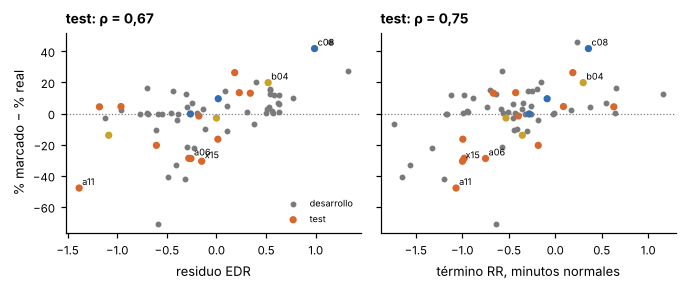

In [3]:
recta = np.polyfit(ND["apnea real (%)"], ND["término EDR"], 1)
for N_ in (NT, ND):
    N_["residuo EDR"] = N_["término EDR"] - np.polyval(recta, N_["apnea real (%)"])
    N_["error (%)"] = N_["marcado (%)"] - N_["apnea real (%)"]
con = NT[NT["evaluados (%)"] > 50]
rho_res, rho_rr = spearmanr(con["residuo EDR"], con["error (%)"])[0], spearmanr(con["término RR, minutos normales"], con["error (%)"])[0]

fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.7), sharey=True)
for ax, col, rho_ in ((axs[0], "residuo EDR", rho_res), (axs[1], "término RR, minutos normales", rho_rr)):
    ax.scatter(ND[col], ND["error (%)"], s=8, color=GRIS, label="desarrollo")
    ax.scatter(con[col], con["error (%)"], s=14, c=[COLORES_CAT[c] for c in con["categoría"]], label="test")
    for r_ in ("a11", "x15", "a06", "c08", "b04"):
        ax.annotate(r_, (con.loc[r_, col], con.loc[r_, "error (%)"]), fontsize=6, xytext=(2, 2), textcoords="offset points")
    ax.axhline(0, color=GRIS, ls=":", lw=0.8)
    ax.set(xlabel=col, title=f"test: ρ = {rho_:.2f}".replace(".", ","))
axs[0].set_ylabel("% marcado − % real")
axs[0].legend(fontsize=6, loc="lower right")
fig.tight_layout()
save(fig, "06_error_por_noche")
print(f"ρ (residuo EDR, error) en test: {rho_res:.2f} · en desarrollo con las mismas definiciones: "
      f"{spearmanr(ND['residuo EDR'], ND['error (%)'])[0]:.2f}")
print(f"ρ (término RR en minutos normales, error) en test: {rho_rr:.2f} · en desarrollo: "
      f"{spearmanr(ND['término RR, minutos normales'], ND['error (%)'])[0]:.2f}")

**Qué se ve.** El error de cada noche crece con las dos cosas (se excluyen c04 y x29, que tienen menos de la mitad de los minutos evaluados):
- con el **residuo de la EDR**, es decir, cuando el nivel de la EDR no corresponde a la cantidad de apnea: ρ = 0,67 en test y 0,51 en desarrollo;
- con el **nivel del RR en los minutos normales**, es decir, en personas cuyo RR oscila mucho o poco en la banda aunque no tengan apnea: ρ = 0,75 en test y 0,40 en desarrollo.

Las dos son propiedades de la persona o de la noche, no del minuto. Por eso los errores vienen en noches enteras. Es el mismo patrón que en desarrollo, incluso más marcado.

## 3. Las noches con la mayoría de los minutos excluidos

c04 y x29 son de la misma persona, un control. Se evalúan solo el 27 % y el 15 % de sus minutos, porque en el resto más del 20 % de los RR quedan corregidos. ¿Es un problema del ECG o del detector de latidos?

PosixPath('/home/user/TP-PSB-G8/informe/figuras/06_ritmo_irregular.png')

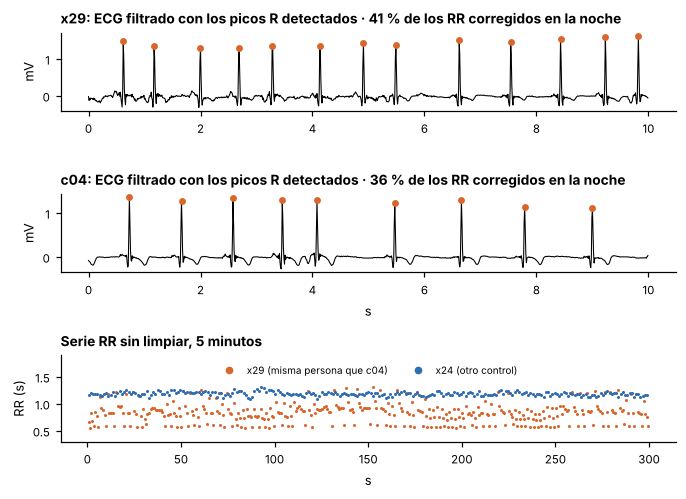

In [4]:
fig, axs = plt.subplots(3, 1, figsize=(ANCHO, 4.6), gridspec_kw={"height_ratios": [1, 1, 1.1]})
for ax, (r_, t0) in zip(axs[:2], (("x29", 3600), ("c04", 3600))):
    ecg, fs = load_ecg(r_)
    x = apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))
    t_r = record_beats(r_)["t_r"]
    i0, i1 = int(t0 * fs), int((t0 + 10) * fs)
    ax.plot(np.arange(i0, i1) / fs - t0, x[i0:i1], color="black", lw=0.7)
    s_ = (t_r >= t0) & (t_r < t0 + 10)
    ax.plot(t_r[s_] - t0, x[np.rint(t_r[s_] * fs).astype(int)], "o", color=APNEA, ms=3.5)
    _, rr_, corr_ = clean_rr(t_r)
    ax.set(ylabel="mV", title=f"{r_}: ECG filtrado con los picos R detectados · {100 * corr_.mean():.0f} % de los RR corregidos en la noche")
axs[1].set_xlabel("s")
comp = [("x29", APNEA), ("x24", NORMAL)]
for r_, color in comp:
    t_r = record_beats(r_)["t_r"]
    rr_ = np.diff(t_r); s_ = (t_r[1:] >= 3600) & (t_r[1:] < 3900)
    axs[2].plot(t_r[1:][s_] - 3600, rr_[s_], ".", ms=2, color=color, label=f"{r_} ({'misma persona que c04' if r_ == 'x29' else 'otro control'})")
axs[2].set(xlabel="s", ylabel="RR (s)", title="Serie RR sin limpiar, 5 minutos", ylim=(0.3, 1.9))
axs[2].legend(fontsize=6.5, loc="upper center", ncol=2, markerscale=4, frameon=False)
fig.tight_layout()
save(fig, "06_ritmo_irregular")

**Qué se ve.** El ECG está limpio y el detector encuentra cada latido. Lo que pasa es que **el ritmo es muy irregular**: hay muchos intervalos cortos (una banda cerca de 0,58 s) mezclados con otros de 0,7 a 1,3 s, y el RR salta de un latido al siguiente. En otro control (x24) la serie RR es una curva suave. Ese ritmo es compatible con latidos prematuros muy frecuentes u otra arritmia; no se puede diagnosticar con estos datos. La limpieza del RR trata como error cualquier RR que se aparte más de un 20 % de la mediana de sus vecinos, así que en este ritmo corrige el 36–41 % de los latidos y excluye la mayoría de los minutos. **El método supone ritmo sinusal**: con una arritmia sostenida, la serie RR no refleja la modulación por la respiración ni por la apnea.

## 4. Conclusión del análisis posterior

| Tipo de error | Noches de test | Causa | ¿Se había visto en desarrollo? |
|---|---|---|---|
| Noche con apnea subestimada por la EDR | a11 | El nivel nocturno de la EDR es bajo para su cantidad de apnea | Sí, es el fallo principal (`04`, sección 11) |
| Noche con apnea subestimada por el RR | a06, x15 (una persona) | El RR responde poco al ciclo de la apnea | Sí, en menor medida |
| Control sobreestimado | c08, b04 (una persona) | El RR tiene mucha potencia en la banda aunque no haya apnea | Sí (x17 en desarrollo) |
| Minutos excluidos | c04, x29 (una persona) | Ritmo muy irregular: la limpieza del RR lo toma como error | No con esta magnitud |

Los tres primeros son del mismo tipo: **dependen de la persona o de la noche, no del minuto**. El RR ubica bien la apnea dentro de cada noche (P1). El error está en dónde queda la vara de cada noche, que depende del nivel de la EDR y del nivel general del RR de la persona. Una mejora futura tendría que estimar mejor la cantidad de apnea de cada noche, por ejemplo combinando el nivel de la EDR con otra medida nocturna. No se prueba acá: haría falta otra base para evaluarla sin usar test.

El cuarto es una limitación del alcance: el método supone ritmo sinusal y no está pensado para arritmias sostenidas.